# 01 · Integración y calidad de los datos

Este notebook une los archivos anuales de Estadísticas Policiales del OIJ, revisa su calidad y genera la tabla base del proyecto: **delitos por cantón, mes y tipo de delito**.

**Fuente:** [Portal de Datos Abiertos del Poder Judicial](https://datosabiertospj.poder-judicial.go.cr/dataset/estadisticas-policiales), licencia Creative Commons Attribution.

Para obtener todos los años: `python scripts/descargar_oij.py`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib.pyplot as plt

from src import oij

pd.set_option('display.width', 120)

## 1. Carga de todos los años disponibles

In [2]:
df = oij.cargar_todos(RAIZ / 'data' / 'raw')
resumen = df.groupby(['Anio', 'Archivo']).agg(registros=('Delito', 'size'),
                                              desde=('Fecha', 'min'), hasta=('Fecha', 'max'))
resumen

,,registros,desde,hasta
Anio,Archivo,,,
2015,PJCROD_POLICIALES_V1-2015.xls,54933,2015-01-01,2015-12-31
2026,PJCROD_POLICIALES_V1-2026.xlsx,27483,2026-01-01,2026-10-08


## 2. Perfil de calidad

Porcentaje de valores vacíos o desconocidos por columna.

In [3]:
oij.perfil_calidad(df)

,columna,categorias,pct_vacio_o_desconocido
0,Delito,6,0.00
1,SubDelito,39,0.07
2,Fecha,646,0.00
3,Victima,4,0.00
4,SubVictima,80,0.00
5,Edad,4,4.75
6,Genero,1,100.00
7,Nacionalidad,104,9.20
8,Provincia,8,0.00
9,Canton,82,0.21


**Lectura:**

- Fecha, delito y ubicación están prácticamente completas: son las variables clave del modelo.
- `Genero` está vacía en todos los registros, así que se descarta.
- No existe columna de hora: el análisis temporal se hace por día, mes y día de la semana.

## 3. Filas idénticas

No hay un identificador de caso, así que las filas repetidas pueden ser varias víctimas de un mismo hecho. Se conservan y se documenta su volumen.

In [4]:
dup = df.duplicated(subset=oij.COLUMNAS).groupby(df['Anio']).mean().mul(100).round(1)
dup.rename('% filas idénticas').to_frame()

,% filas idénticas
Anio,
2015,6.1
2026,10.6


## 4. Armonización de cantones

Río Cuarto (2017), Monteverde (2021) y Puerto Jiménez (2022) se crearon dentro del periodo. Se reasignan a su cantón de origen para que las series sean comparables.

In [5]:
cambios = df[df['Canton_original'] != df['Canton']]
cambios.groupby(['Canton_original', 'Canton']).size().rename('registros').to_frame()

,,registros
Canton_original,Canton,
MONTEVERDE,PUNTARENAS,96
PUERTO JIMENEZ,GOLFITO,55
RIO CUARTO,GRECIA,51


In [6]:
print('Cantones tras armonizar:', df.loc[~df['Canton'].isin(oij.VALORES_DESCONOCIDOS), 'Canton'].nunique())

Cantones tras armonizar: 81


## 5. Tabla base: delitos por cantón, mes y tipo

Se excluyen los registros sin cantón conocido y el mes en curso (incompleto). La rejilla incluye ceros para las combinaciones sin delitos.

In [7]:
base = oij.agregar_mensual(df)
print(base.shape)
print('Meses:', base['Mes'].min(), '→', base['Mes'].max())
base.head()

Aviso: no hay datos para los años 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025; descárgalos con scripts/descargar_oij.py
(10206, 5)
Meses: 2015-01 → 2026-09


,Provincia,Canton,Mes,Delito,Delitos
0,GUANACASTE,ABANGARES,2015-01,HURTO,4
1,GUANACASTE,ABANGARES,2015-01,ASALTO,0
2,GUANACASTE,ABANGARES,2015-01,ROBO,5
3,GUANACASTE,ABANGARES,2015-01,ROBO DE VEHICULO,1
4,GUANACASTE,ABANGARES,2015-01,TACHA DE VEHICULO,1


In [8]:
fuera = df['Canton'].isin(oij.VALORES_DESCONOCIDOS).sum()
print(f'Registros sin cantón conocido excluidos: {fuera} ({100*fuera/len(df):.2f} %)')
print('Último mes completo:', oij.ultimo_mes_completo(df))

Registros sin cantón conocido excluidos: 174 (0.21 %)
Último mes completo: 2026-09


## 6. Primera mirada: total nacional por tipo de delito

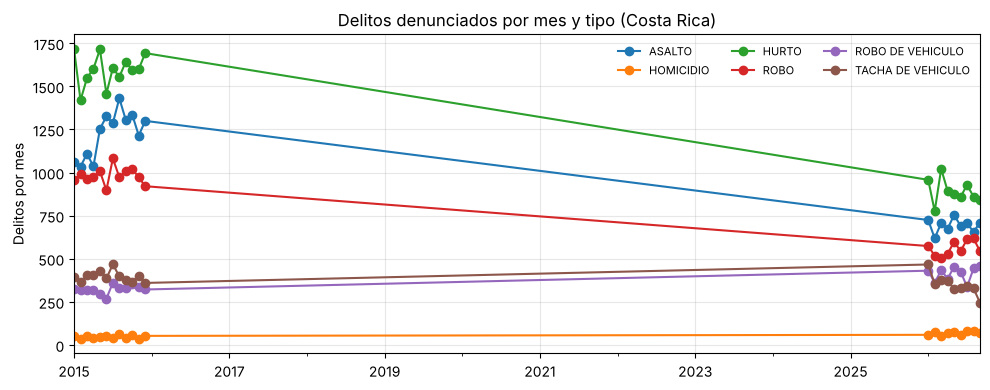

In [9]:
nacional = base.groupby(['Mes', 'Delito'])['Delitos'].sum().unstack()
fig, ax = plt.subplots(figsize=(10, 4))
nacional.plot(ax=ax, marker='o', lw=1.5)
ax.set_ylabel('Delitos por mes'); ax.set_xlabel('')
ax.set_title('Delitos denunciados por mes y tipo (Costa Rica)')
ax.legend(ncol=3, fontsize=8, frameon=False)
ax.grid(alpha=.3)
plt.tight_layout()
fig.savefig(RAIZ / 'reports' / 'figures' / '01_total_mensual_por_delito.png', dpi=150)

## 7. Guardar

In [10]:
salida = RAIZ / 'data' / 'processed' / 'delitos_canton_mes.parquet'
base.assign(Mes=base['Mes'].astype(str)).to_parquet(salida, index=False)
print('Guardado en', salida)

Guardado en /home/claude/tfm---isaac-sanchez/data/processed/delitos_canton_mes.parquet
